# 20 — First 12:00 intraday update

The experiment was executed locally through `build_intraday_noon_update.py`. These cells inspect saved results. The daily-only control isolates the contribution of current-session information.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Image
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'blackrock_data').exists())
out = root / 'outputs/experiments/20_intraday_noon'

,candidate,development_rmse_log,development_wape,development_bias,confirmation_rmse_log,confirmation_wape,confirmation_bias
0,checkpoint_ratio_rule,0.762570,0.541024,-0.118642,0.688487,0.523167,-0.047689
1,fixed_daily,0.469491,0.354676,-0.144684,0.429014,0.328298,-0.090003
2,lgbm_daily_control,0.479021,0.359621,-0.133428,0.429881,0.331893,-0.071872
3,lgbm_intraday_update,0.469099,0.352445,-0.131024,0.421091,0.324393,-0.070317
4,ridge_update,0.464589,0.348529,-0.130164,0.416770,0.322457,-0.075256


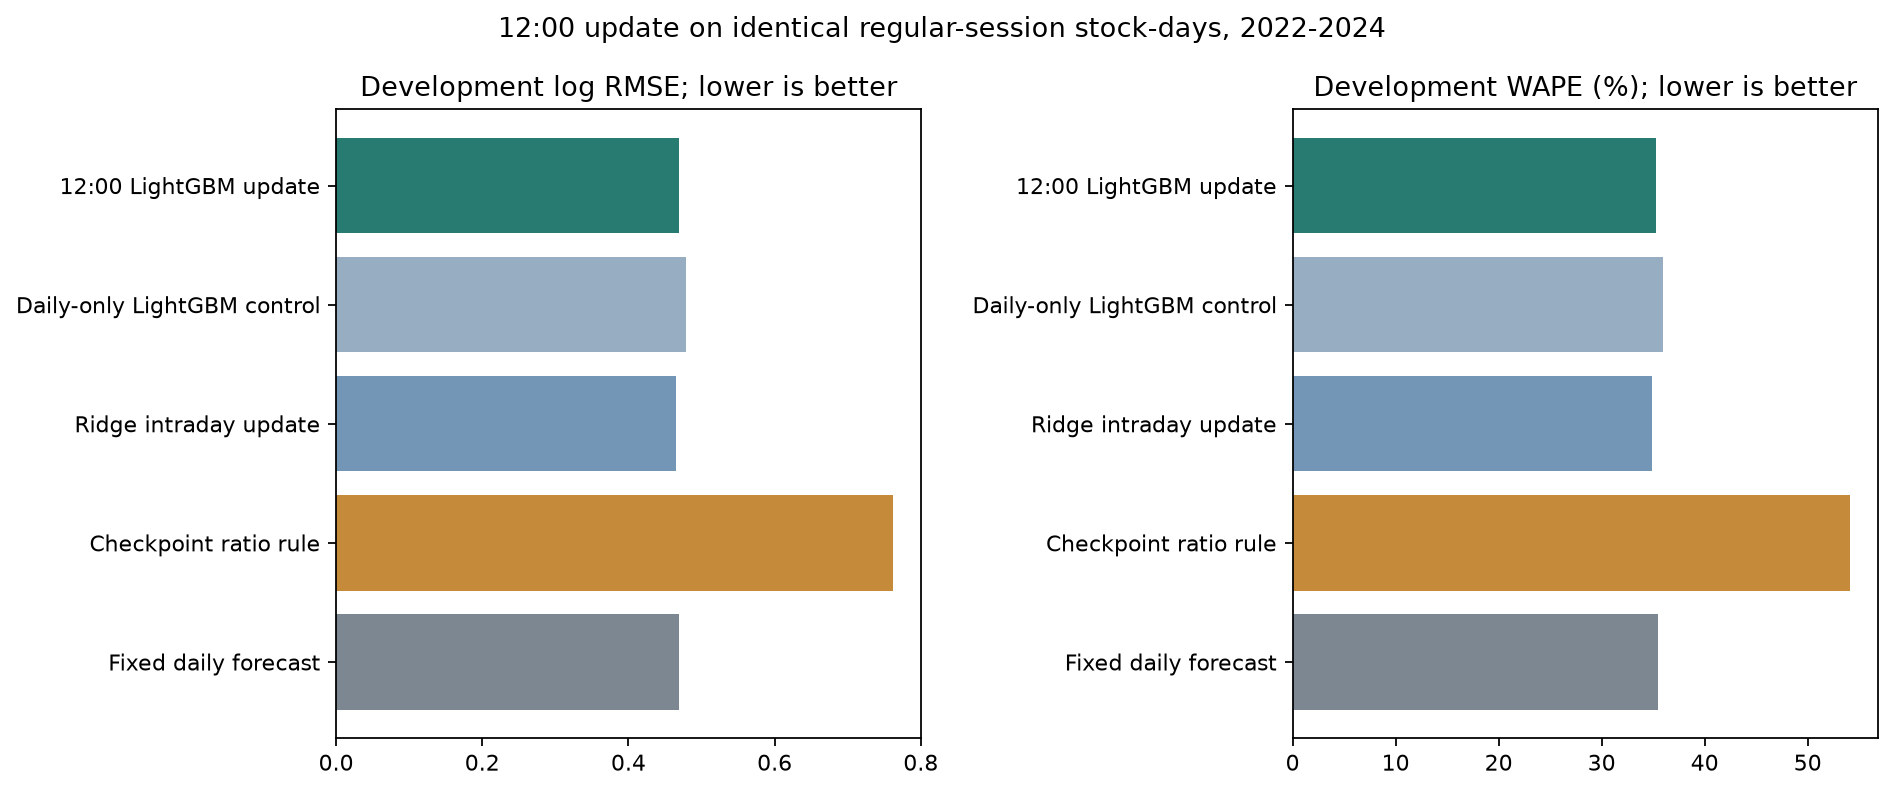

In [2]:
display(pd.read_csv(out / 'intraday_comparison.csv'))
display(Image(filename=str(out / 'intraday_comparison.png')))

In [3]:
display(pd.read_csv(out / 'coverage_by_year.csv'))
display(pd.read_csv(out / 'intraday_information_gate.csv'))
display(pd.read_csv(out / 'paired_bootstrap.csv'))

,year,eligible_targets,early_close_rows,regular_session_rows,valid_checkpoint_rows,daily_fallback_rows,invalid_daily_forecasts
0,2021,321564,1294,320270,320010,260,0
1,2022,328634,1279,327355,326861,494,0
2,2023,318679,2520,316159,315980,179,0
3,2024,316212,3730,312482,312457,25,0
4,2025,307853,3681,304172,304152,20,0


,reference,rmse_change,worst_annual_rmse_change,wape_change,paired_log_mae_ci_upper,passes
0,fixed_daily,-0.000392,0.003503,-0.002231,-0.000571,False
1,lgbm_daily_control,-0.009922,-0.008634,-0.007175,-0.007951,True


,candidate,reference,period,metric,dates,mean_difference,ci_2_5,ci_97_5
0,checkpoint_ratio_rule,fixed_daily,development,log_mae_delta,747,0.199229,0.187647,0.212105
1,checkpoint_ratio_rule,fixed_daily,development,daily_wape_delta,747,0.172499,0.166157,0.178980
2,checkpoint_ratio_rule,fixed_daily,confirmation,log_mae_delta,247,0.184891,0.165988,0.209518
3,checkpoint_ratio_rule,fixed_daily,confirmation,daily_wape_delta,247,0.182714,0.170530,0.195128
4,checkpoint_ratio_rule,lgbm_daily_control,development,log_mae_delta,747,0.192451,0.180195,0.205422
5,checkpoint_ratio_rule,lgbm_daily_control,development,daily_wape_delta,747,0.167148,0.159929,0.174280
6,checkpoint_ratio_rule,lgbm_daily_control,confirmation,log_mae_delta,247,0.181970,0.162660,0.206643
7,checkpoint_ratio_rule,lgbm_daily_control,confirmation,daily_wape_delta,247,0.178940,0.166300,0.191690
8,ridge_update,fixed_daily,development,log_mae_delta,747,-0.006591,-0.007954,-0.005236
9,ridge_update,fixed_daily,development,daily_wape_delta,747,-0.007180,-0.008349,-0.005954


In [4]:
display(pd.read_csv(out / 'segment_diagnostics.csv'))
checks = pd.read_csv(out / 'validation_checks.csv')
assert checks.passed.all()
display(checks)

,candidate,dimension,segment,observations,rmse_log,wape,aggregate_bias
0,fixed_daily,size,small,289404,0.580339,0.447202,-0.237463
1,fixed_daily,size,mid,337117,0.431558,0.388017,-0.177834
2,fixed_daily,size,large,329475,0.396853,0.329388,-0.120311
3,fixed_daily,history,seasoned,952795,0.467838,0.353337,-0.143927
4,fixed_daily,history,developing_5_19,2451,0.877127,0.461889,-0.261419
...,...,...,...,...,...,...,...
65,lgbm_intraday_update,event,regular,864853,0.447888,0.308459,-0.089518
66,lgbm_intraday_update,event,quarterly_expiry,15431,0.760923,0.535424,-0.280808
67,lgbm_intraday_update,event,month_end,44999,0.674368,0.478432,-0.297297
68,lgbm_intraday_update,availability,available,955298,0.469520,0.351257,-0.130183


,check,passed
0,forbidden_current_daily_outcomes_not_inputs,True
1,2022_unique_keys,True
2,2022_proper_year,True
3,2022_all_regular_session_keys_and_labels,True
4,2022_daily_reference_unchanged,True
...,...,...
119,2025_lgbm_intraday_update_feature_allowlist,True
120,2025_lgbm_intraday_update_serialized_model_rec...,True
121,independent_prior_window_checkpoint_avg_volume20,True
122,independent_prior_window_checkpoint_avg_trades20,True


## Noon versus 15:30

Exact evaluation keys and daily reference match across both checkpoints. Positive paired differences mean lower errors at 15:30. Noon LightGBM does not pass the full prespecified gate against the fixed daily forecast.

In [5]:
display(pd.read_csv(out / 'checkpoint_time_comparison.csv'))
display(pd.read_csv(out / 'paired_checkpoint_time_bootstrap.csv'))
display(pd.read_csv(out / 'timing_alignment_checks.csv'))
display(pd.read_csv(out / 'full_checkpoint_availability_audit.csv'))

,checkpoint,candidate,development_rmse_log,development_wape,development_bias,confirmation_rmse_log,confirmation_wape,confirmation_bias
0,12:00,checkpoint_ratio_rule,0.762570,0.541024,-0.118642,0.688487,0.523167,-0.047689
1,12:00,fixed_daily,0.469491,0.354676,-0.144684,0.429014,0.328298,-0.090003
2,12:00,lgbm_daily_control,0.479021,0.359621,-0.133428,0.429881,0.331893,-0.071872
3,12:00,lgbm_intraday_update,0.469099,0.352445,-0.131024,0.421091,0.324393,-0.070317
4,12:00,ridge_update,0.464589,0.348529,-0.130164,0.416770,0.322457,-0.075256
5,15:30,checkpoint_ratio_rule,0.691529,0.492621,-0.156346,0.614224,0.466934,-0.090475
6,15:30,fixed_daily,0.469491,0.354676,-0.144684,0.429014,0.328298,-0.090003
7,15:30,lgbm_daily_control,0.478712,0.359470,-0.133879,0.430338,0.332277,-0.071158
8,15:30,lgbm_intraday_update,0.462146,0.347655,-0.119335,0.415594,0.321218,-0.058610
9,15:30,ridge_update,0.459954,0.345919,-0.118001,0.409157,0.317815,-0.069106


,method,period,metric,noon_minus_1530,ci_lower,ci_upper
0,ridge_update,development,log_mae_delta,0.003419,0.002904,0.003927
1,ridge_update,development,daily_wape_delta,0.002171,0.001521,0.002777
2,ridge_update,confirmation,log_mae_delta,0.007220,0.006473,0.007958
3,ridge_update,confirmation,daily_wape_delta,0.004546,0.003625,0.005477
4,lgbm_intraday_update,development,log_mae_delta,0.004887,0.004245,0.005571
5,lgbm_intraday_update,development,daily_wape_delta,0.003734,0.002969,0.004479
6,lgbm_intraday_update,confirmation,log_mae_delta,0.003332,0.002154,0.004471
7,lgbm_intraday_update,confirmation,daily_wape_delta,0.002370,0.000998,0.003657


,year,rows,keys_labels_daily_reference_exact
0,2022,327355,True
1,2023,316159,True
2,2024,312482,True
3,2025,304172,True


,checkpoint,source_availability_mismatches
0,12:00,0
1,15:30,0
